In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Environment ready!")

Environment ready!


In [2]:
from pathlib import Path

DATA_PATH = Path("../data/raw")

print("Folder exists:", DATA_PATH.exists())
print("Number of CSV files:", len(list(DATA_PATH.glob("*.csv"))))

for file in DATA_PATH.glob("*.csv"):
    print(file.name)

Folder exists: True
Number of CSV files: 9
olist_customers_dataset.csv
olist_geolocation_dataset.csv
olist_orders_dataset.csv
olist_order_items_dataset.csv
olist_order_payments_dataset.csv
olist_order_reviews_dataset.csv
olist_products_dataset.csv
olist_sellers_dataset.csv
product_category_name_translation.csv


In [3]:
customers = pd.read_csv(DATA_PATH / "olist_customers_dataset.csv")
orders = pd.read_csv(DATA_PATH / "olist_orders_dataset.csv")
items = pd.read_csv(DATA_PATH / "olist_order_items_dataset.csv")
products = pd.read_csv(DATA_PATH / "olist_products_dataset.csv")
payments = pd.read_csv(DATA_PATH / "olist_order_payments_dataset.csv")
reviews = pd.read_csv(DATA_PATH / "olist_order_reviews_dataset.csv")
sellers = pd.read_csv(DATA_PATH / "olist_sellers_dataset.csv")
geolocation = pd.read_csv(DATA_PATH / "olist_geolocation_dataset.csv")
categories = pd.read_csv(DATA_PATH / "product_category_name_translation.csv")

print("All datasets loaded!")

All datasets loaded!


In [4]:
datasets = {
    "customers": customers,
    "orders": orders,
    "items": items,
    "products": products,
    "payments": payments,
    "reviews": reviews,
    "sellers": sellers,
    "geolocation": geolocation,
    "categories": categories
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

customers: (99441, 5)
orders: (99441, 8)
items: (112650, 7)
products: (32951, 9)
payments: (103886, 5)
reviews: (99224, 7)
sellers: (3095, 4)
geolocation: (1000163, 5)
categories: (71, 2)


In [5]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [6]:
for name, df in datasets.items():

    print("\n" + "="*60)
    print(f"DATASET: {name.upper()}")
    print("="*60)

    print("Shape:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())


DATASET: CUSTOMERS
Shape: (99441, 5)

Data types:
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

Missing values:
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Duplicate rows: 0

DATASET: ORDERS
Shape: (99441, 8)

Data types:
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

Missing values:
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
o

In [7]:
quality_report = []

for name, df in datasets.items():

    quality_report.append({
        "Dataset": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Memory (MB)": round(
            df.memory_usage(deep=True).sum() / (1024**2), 2
        )
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Memory (MB)
0,customers,99441,5,0,0,11.03
1,orders,99441,8,4908,0,21.95
2,items,112650,7,0,0,18.37
3,products,32951,9,2448,0,3.73
4,payments,103886,5,0,0,8.11
5,reviews,99224,7,145903,0,17.84
6,sellers,3095,4,0,0,0.22
7,geolocation,1000163,5,0,261831,50.12
8,categories,71,2,0,0,0.00


In [8]:
print("Total customer records:",
      len(customers))

print("Unique customer IDs:",
      customers["customer_id"].nunique())

print("Unique actual customers:",
      customers["customer_unique_id"].nunique())

print("Customers with multiple order records:",
      customers["customer_unique_id"].duplicated().sum())

Total customer records: 99441
Unique customer IDs: 99441
Unique actual customers: 96096
Customers with multiple order records: 3345


In [9]:
# Missing values by column

for name, df in datasets.items():

    missing = df.isnull().sum()

    if missing.sum() > 0:
        print("\n", "="*50)
        print("DATASET:", name.upper())

        report = pd.DataFrame({
            "Missing_Count": missing,
            "Missing_Percentage": (
                missing / len(df) * 100
            ).round(2)
        })

        print(report[report["Missing_Count"] > 0])


DATASET: ORDERS
                               Missing_Count  Missing_Percentage
order_approved_at                        160                0.16
order_delivered_carrier_date            1783                1.79
order_delivered_customer_date           2965                2.98

DATASET: PRODUCTS
                            Missing_Count  Missing_Percentage
product_category_name                 610                1.85
product_name_lenght                   610                1.85
product_description_lenght            610                1.85
product_photos_qty                    610                1.85
product_weight_g                        2                0.01
product_length_cm                       2                0.01
product_height_cm                       2                0.01
product_width_cm                        2                0.01

DATASET: REVIEWS
                        Missing_Count  Missing_Percentage
review_comment_title            87656               88.34
review_comme

In [10]:
print("Review dataset shape:", reviews.shape)

print("\nReview scores:")
print(reviews["review_score"].value_counts().sort_index())

print("\nMissing review values:")
print(reviews.isnull().sum())

Review dataset shape: (99224, 7)

Review scores:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

Missing review values:
review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64


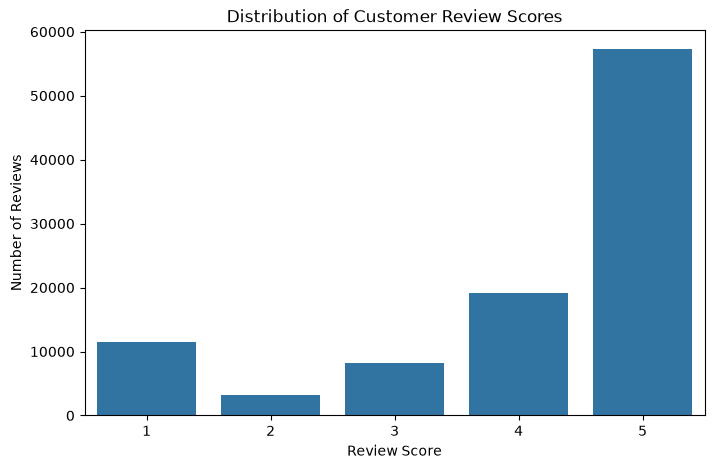

In [11]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=reviews,
    x="review_score"
)

plt.title("Distribution of Customer Review Scores")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.show()

In [12]:
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


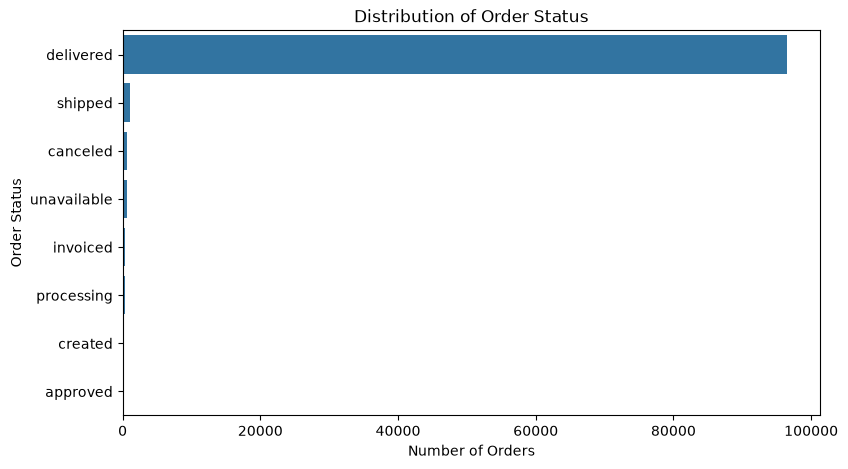

In [13]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=orders,
    y="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Distribution of Order Status")
plt.xlabel("Number of Orders")
plt.ylabel("Order Status")

plt.show()

In [14]:
customer_order_counts = (
    customers.groupby("customer_unique_id")
    .size()
    .reset_index(name="order_count")
)

# Customers who have more than one order
repeat_customers = customer_order_counts[
    customer_order_counts["order_count"] > 1
]

print("Total unique customers:",
      len(customer_order_counts))

print("Customers with repeat orders:",
      len(repeat_customers))

print("Repeat customer percentage:",
      round(len(repeat_customers) /
            len(customer_order_counts) * 100, 2), "%")

print("\nOrder frequency distribution:")
print(customer_order_counts["order_count"].value_counts().sort_index())

Total unique customers: 96096
Customers with repeat orders: 2997
Repeat customer percentage: 3.12 %

Order frequency distribution:
order_count
1     93099
2      2745
3       203
4        30
5         8
6         6
7         3
9         1
17        1
Name: count, dtype: int64


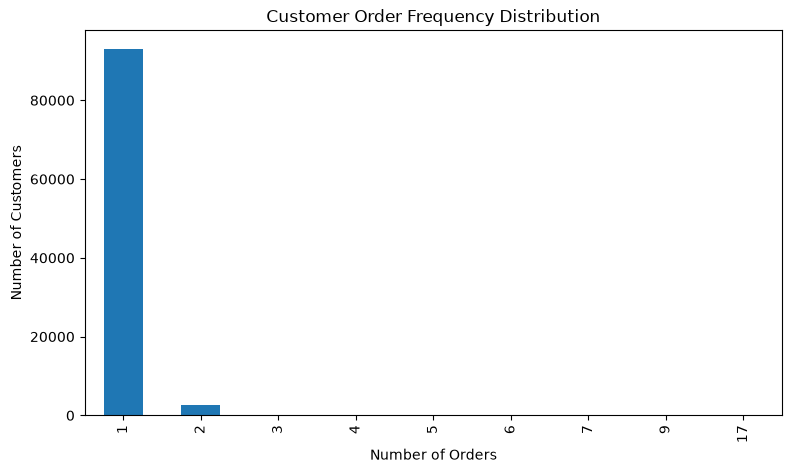

In [15]:
repeat_counts = (
    customer_order_counts["order_count"]
    .value_counts()
    .sort_index()
)

repeat_counts.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Customer Order Frequency Distribution")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.show()

In [16]:
orders.info()

orders.head()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 21.9 MB


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [17]:
customer_order_counts = (
    customers.groupby("customer_unique_id")
    .size()
)

print(customer_order_counts.describe())

count    96096.000000
mean         1.034809
std          0.214384
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         17.000000
dtype: float64


In [18]:
print("Unique product categories:",
      products["product_category_name"].nunique())

print("\nTop product categories:")

print(
    products["product_category_name"]
    .value_counts()
    .head(15)
)

Unique product categories: 73

Top product categories:
product_category_name
cama_mesa_banho                3029
esporte_lazer                  2867
moveis_decoracao               2657
beleza_saude                   2444
utilidades_domesticas          2335
automotivo                     1900
informatica_acessorios         1639
brinquedos                     1411
relogios_presentes             1329
telefonia                      1134
bebes                           919
perfumaria                      868
papelaria                       849
fashion_bolsas_e_acessorios     849
cool_stuff                      789
Name: count, dtype: int64


In [19]:
print(items[["price", "freight_value"]].describe())

               price  freight_value
count  112650.000000  112650.000000
mean      120.653739      19.990320
std       183.633928      15.806405
min         0.850000       0.000000
25%        39.900000      13.080000
50%        74.990000      16.260000
75%       134.900000      21.150000
max      6735.000000     409.680000


In [20]:
# Preserve original data
orders_clean = orders.copy()

# Columns containing timestamps
date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

# Convert strings into datetime objects
for col in date_columns:
    orders_clean[col] = pd.to_datetime(
        orders_clean[col],
        errors="coerce"
    )

# Verify conversion
print(orders_clean[date_columns].dtypes)

display(orders_clean[date_columns].head())

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


In [21]:
# Work only with orders that were actually delivered
delivered_orders = orders_clean[
    orders_clean["order_status"] == "delivered"
].copy()

# Calculate actual delivery duration in days
delivered_orders["delivery_duration"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate delivery delay in days
delivered_orders["delivery_delay"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

# Positive = late, negative = early
print(delivered_orders[
    ["delivery_duration", "delivery_delay"]
].describe())

       delivery_duration  delivery_delay
count       96470.000000    96470.000000
mean           12.558217      -11.178126
std             9.546156       10.184354
min             0.533414     -146.016123
25%             6.766204      -16.244065
50%            10.217477      -11.948102
75%            15.720182       -6.389815
max           209.628611      188.975081


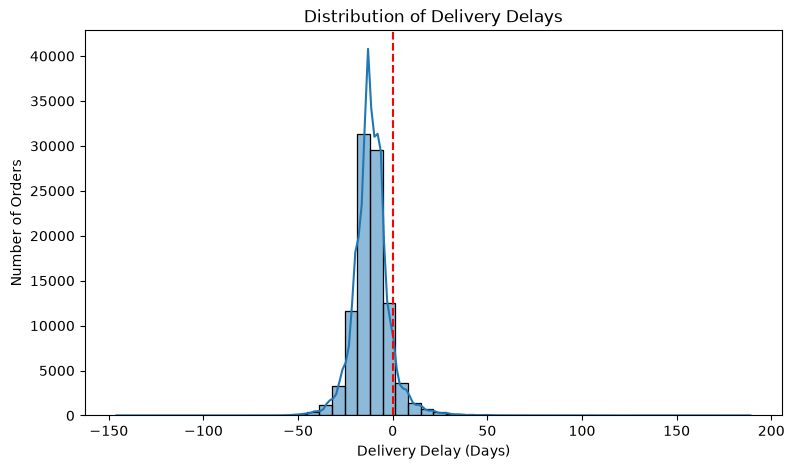

In [22]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=delivered_orders,
    x="delivery_delay",
    bins=50,
    kde=True
)

plt.axvline(0, linestyle="--", color="red")

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Orders")

plt.show()

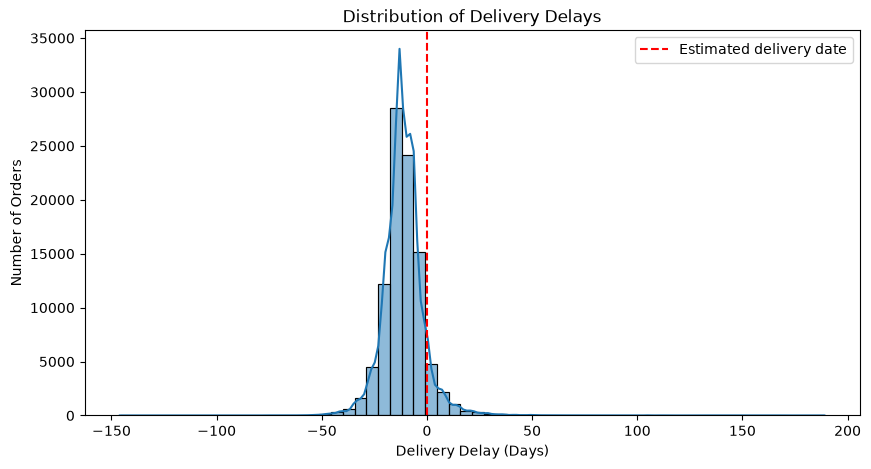

In [23]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivered_orders,
    x="delivery_delay",
    bins=60,
    kde=True
)

plt.axvline(0, linestyle="--", color="red", label="Estimated delivery date")

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Orders")
plt.legend()
plt.show()

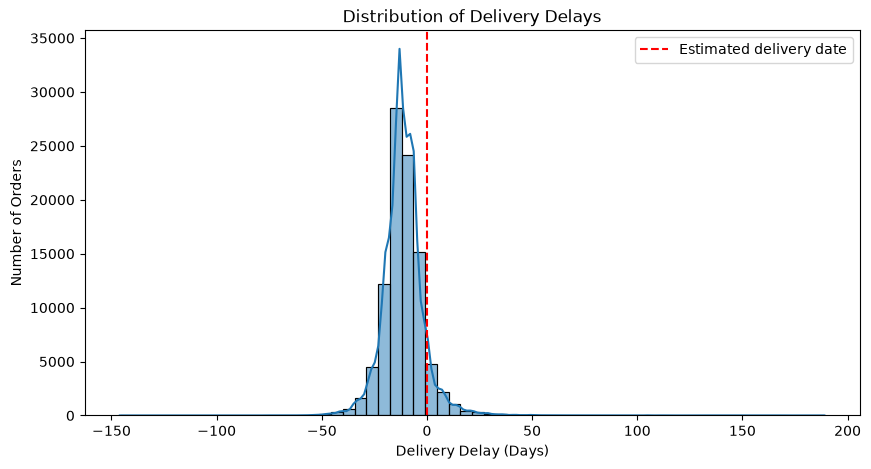

In [24]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivered_orders,
    x="delivery_delay",
    bins=60,
    kde=True
)

plt.axvline(0, linestyle="--", color="red", label="Estimated delivery date")

plt.title("Distribution of Delivery Delays")
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Orders")
plt.legend()
plt.show()

In [25]:
early = (delivered_orders["delivery_delay"] < 0).sum()

on_time = (delivered_orders["delivery_delay"] == 0).sum()

late = (delivered_orders["delivery_delay"] > 0).sum()

total = early + on_time + late

print("Early deliveries:", early)
print("On-time deliveries:", on_time)
print("Late deliveries:", late)

print("\nPercentages:")
print("Early:", round(early / total * 100, 2), "%")
print("On-time:", round(on_time / total * 100, 2), "%")
print("Late:", round(late / total * 100, 2), "%")

Early deliveries: 88644
On-time deliveries: 0
Late deliveries: 7826

Percentages:
Early: 91.89 %
On-time: 0.0 %
Late: 8.11 %


In [26]:
# 10 orders delivered earliest relative to estimated date
print("Extremely early deliveries:")
display(
    delivered_orders.nsmallest(10, "delivery_delay")[
        ["order_id", "order_purchase_timestamp",
         "order_delivered_customer_date",
         "order_estimated_delivery_date",
         "delivery_duration", "delivery_delay"]
    ]
)

# 10 orders delivered latest relative to estimated date
print("Extremely late deliveries:")
display(
    delivered_orders.nlargest(10, "delivery_delay")[
        ["order_id", "order_purchase_timestamp",
         "order_delivered_customer_date",
         "order_estimated_delivery_date",
         "delivery_duration", "delivery_delay"]
    ]
)

Extremely early deliveries:


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration,delivery_delay
40094,0607f0efea4b566f1eb8f7d3c2397320,2018-03-06 09:47:07,2018-03-09 23:36:47,2018-08-03,3.576157,-146.016123
15791,c72727d29cde4cf870d569bf65edabfd,2017-02-07 18:01:15,2017-02-14 14:27:45,2017-07-04,6.851736,-139.397396
57160,eec7f369423b033e549c02f3c5381205,2018-02-06 20:44:56,2018-02-27 16:35:43,2018-07-12,20.826933,-134.308530
86444,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2017-06-09 13:35:54,2017-10-11,16.630069,-123.433403
67488,40dc2ba6f322a17626aac6244332828c,2017-10-05 21:39:05,2017-10-13 13:49:07,2018-01-30,7.673634,-108.424225
79449,1a695d543b7302aa9446c8d5fbd632bf,2017-12-16 10:32:49,2017-12-28 22:18:23,2018-03-22,12.489977,-83.070567
62706,39e0115911bf404857e14baa7f097feb,2018-01-20 07:48:16,2018-02-01 01:52:34,2018-04-25,11.752986,-82.921829
95849,559eea5a72341a4c82dbce9884277cb7,2017-11-17 10:24:03,2017-11-30 16:12:50,2018-02-16,13.242211,-77.324421
63537,38930f76efb00b138f4d632e4d557341,2018-01-28 13:47:42,2018-02-08 19:21:39,2018-04-27,11.231910,-77.193299
37491,c5132855100a12d63ed4e8ae05f9594d,2017-10-13 14:45:03,2017-10-25 20:22:10,2018-01-11,12.234109,-77.151273


Extremely late deliveries:


,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_duration,delivery_delay
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,188.975081
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611,181.608785
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542,175.869109
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160,167.708414
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,166.583380
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,165.633912
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843,162.718345
40847,d24e8541128cea179a11a65176e0a96f,2017-06-12 13:14:11,2017-12-04 18:36:29,2017-06-26,175.223819,161.775336
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,161.609965
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618,159.609931


In [27]:
delivered_orders["calendar_delivery_delay"] = (
    delivered_orders["order_delivered_customer_date"].dt.normalize()
    - delivered_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

early = (delivered_orders["calendar_delivery_delay"] < 0).sum()
on_time = (delivered_orders["calendar_delivery_delay"] == 0).sum()
late = (delivered_orders["calendar_delivery_delay"] > 0).sum()

total = early + on_time + late

print(f"Early: {early} ({early/total*100:.2f}%)")
print(f"On time: {on_time} ({on_time/total*100:.2f}%)")
print(f"Late: {late} ({late/total*100:.2f}%)")

Early: 88644 (91.89%)
On time: 1292 (1.34%)
Late: 6534 (6.77%)


In [28]:
# Count repeated actual delivery timestamps
print(
    delivered_orders["order_delivered_customer_date"]
    .value_counts()
    .head(15)
)

order_delivered_customer_date
2018-05-14 20:02:44    3
2016-10-27 17:32:07    3
2018-05-08 23:38:46    3
2018-07-24 21:36:42    3
2017-12-02 00:26:45    3
2017-06-19 18:47:51    3
2018-05-08 19:36:48    3
2018-02-14 21:09:19    3
2018-03-21 22:03:54    2
2017-05-29 12:47:20    2
2017-07-12 20:17:57    2
2017-07-31 18:17:45    2
2017-03-01 14:09:10    2
2018-07-11 22:52:20    2
2018-07-07 14:41:18    2
Name: count, dtype: int64


In [29]:
delivered_orders["estimated_delivery_days"] = (
    delivered_orders["order_estimated_delivery_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

display(
    delivered_orders["estimated_delivery_days"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

count    96478.000000
mean        23.736347
std          8.760765
min          2.008009
1%           6.053907
5%          10.479559
25%         18.330081
50%         23.230880
75%         28.407590
95%         38.418419
99%         50.211262
max        155.135463
Name: estimated_delivery_days, dtype: float64

In [30]:
suspicious_ids = [
    "0607f0efea4b566f1eb8f7d3c2397320",
    "1b3190b2dfa9d789e1f14c05b647a14a",
    "ca07593549f1816d26a572e06dc1eab6"
]

display(
    orders_clean[orders_clean["order_id"].isin(suspicious_ids)]
)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
19590,ca07593549f1816d26a572e06dc1eab6,75683a92331068e2d281b11a7866ba44,delivered,2017-02-21 23:31:27,2017-02-23 02:35:15,2017-03-08 13:47:46,2017-09-19 14:36:39,2017-03-22
40094,0607f0efea4b566f1eb8f7d3c2397320,a5fbb6579eacbeb02752a143bfe82405,delivered,2018-03-06 09:47:07,2018-03-06 09:55:47,2018-03-07 21:33:39,2018-03-09 23:36:47,2018-08-03
55619,1b3190b2dfa9d789e1f14c05b647a14a,d306426abe5fca15e54b645e4462dc7b,delivered,2018-02-23 14:57:35,2018-02-23 15:16:14,2018-02-26 18:49:07,2018-09-19 23:24:07,2018-03-15


In [31]:
delivery_reviews = delivered_orders.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

print("Merged dataset shape:", delivery_reviews.shape)

display(
    delivery_reviews[
        ["order_id", "calendar_delivery_delay", "review_score"]
    ].head()
)

Merged dataset shape: (96361, 13)


,order_id,calendar_delivery_delay,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,-8.0,4
1,53cdb2fc8bc7dce0b6741e2150273451,-6.0,4
2,47770eb9100c2d0c44946d9cf07ec65d,-18.0,5
3,949d5b44dbf5de918fe9c16f97b45f8a,-13.0,5
4,ad21c59c0840e6cb83a9ceb5573f8159,-10.0,5


In [32]:
delivery_reviews["delivery_category"] = np.select(
    [
        delivery_reviews["calendar_delivery_delay"] < 0,
        delivery_reviews["calendar_delivery_delay"] == 0,
        delivery_reviews["calendar_delivery_delay"] > 0
    ],
    ["Early", "On time", "Late"],
    default="Unknown"
)

delivery_reviews.groupby("delivery_category")["review_score"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
delivery_category,,,
Early,88653,4.293718,5.0
Late,6409,2.271025,1.0
On time,1291,4.033308,5.0
Unknown,8,4.500000,5.0
